In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = sns.load_dataset("taxis")
print(df.head())

<bound method NDFrame.head of                   pickup             dropoff  passengers  distance  fare  \
0    2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0   
1    2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0   
2    2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5   
3    2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0   
4    2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0   
...                  ...                 ...         ...       ...   ...   
6428 2019-03-31 09:51:53 2019-03-31 09:55:27           1      0.75   4.5   
6429 2019-03-31 17:38:00 2019-03-31 18:34:23           1     18.74  58.0   
6430 2019-03-23 22:55:18 2019-03-23 23:14:25           1      4.14  16.0   
6431 2019-03-04 10:09:25 2019-03-04 10:14:29           1      1.12   6.0   
6432 2019-03-13 19:31:22 2019-03-13 19:48:02           1      3.85  15.0   

       tip  tolls  total   color      payment            

In [13]:
print(df.info())
print(df.shape)
print(df.notnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [9]:
print(df.columns[df.isnull().any()])

Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='str')


<h2 style="text-align:center;color:black;background:#6C757D;padding:10px;border-radius:8px;font-size:28px;font-weight:bold;">Visualizations using Matplotlib/Pandas Plot:</h2>

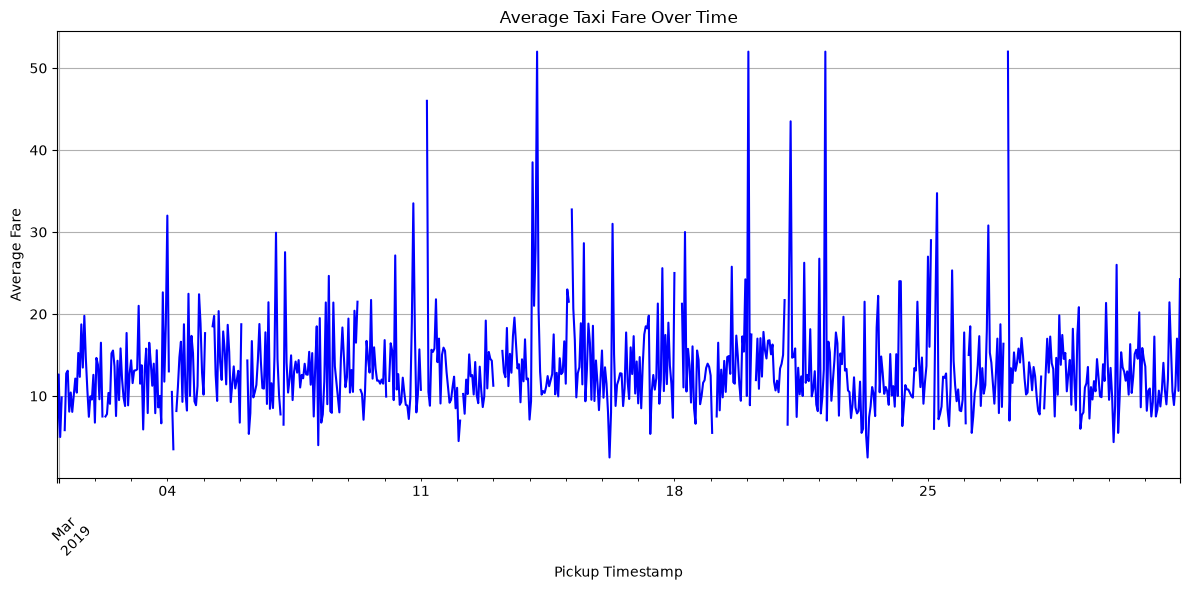

In [ ]:
# Sort data by pickup timestamp
df = df.sort_values('pickup')

# Group fares by hour
hourly_fare = df.set_index('pickup')['fare'].resample('h').mean()

# Plot line chart
plt.figure(figsize=(12, 6))

hourly_fare.plot(kind='line', color='blue')

plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Average Fare')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()



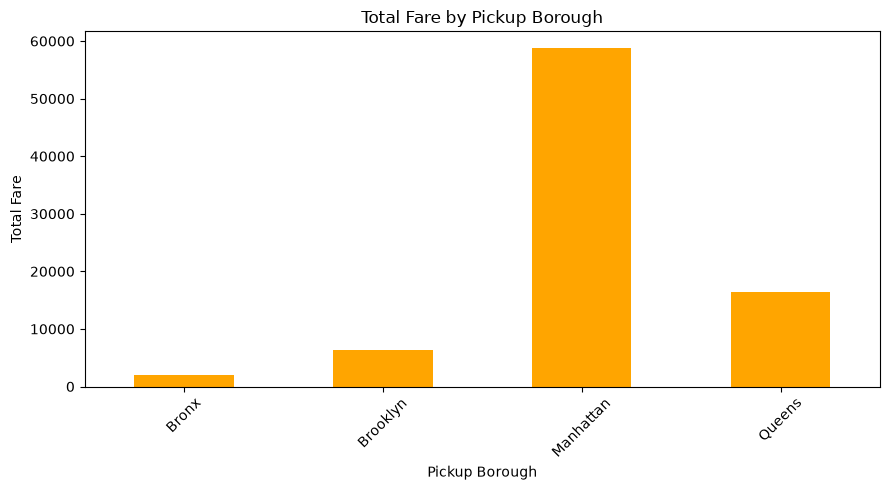

In [15]:
# Group data by pickup borough and calculate total fare
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create bar chart
borough_fare.plot(
    kind='bar',
    figsize=(9, 5),
    color='orange'
)

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

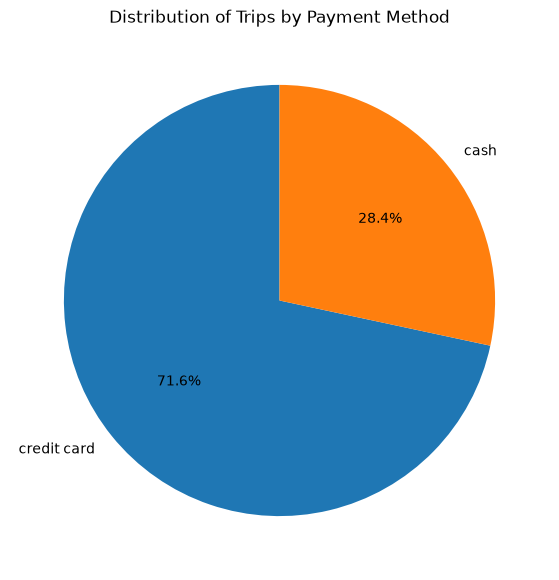

In [16]:
# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')
plt.show()

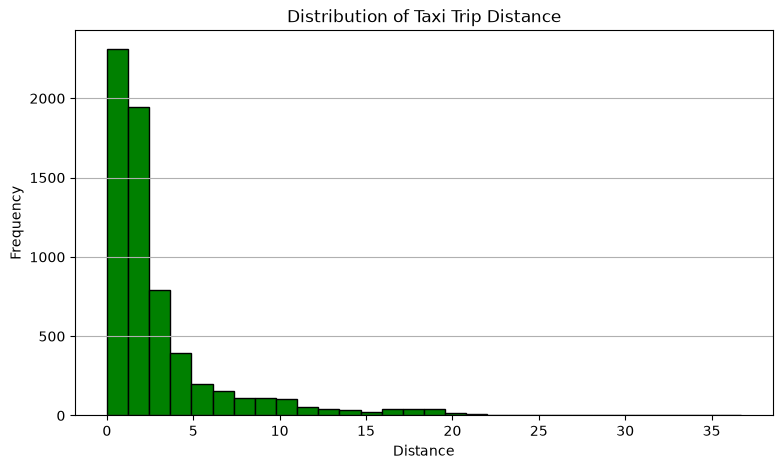

In [17]:
plt.figure(figsize=(9, 5))

plt.hist(
    df['distance'],
    bins=30,
    color='green',
    edgecolor='black'
)

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.grid(axis='y')
plt.show()

<Figure size 1000x500 with 0 Axes>

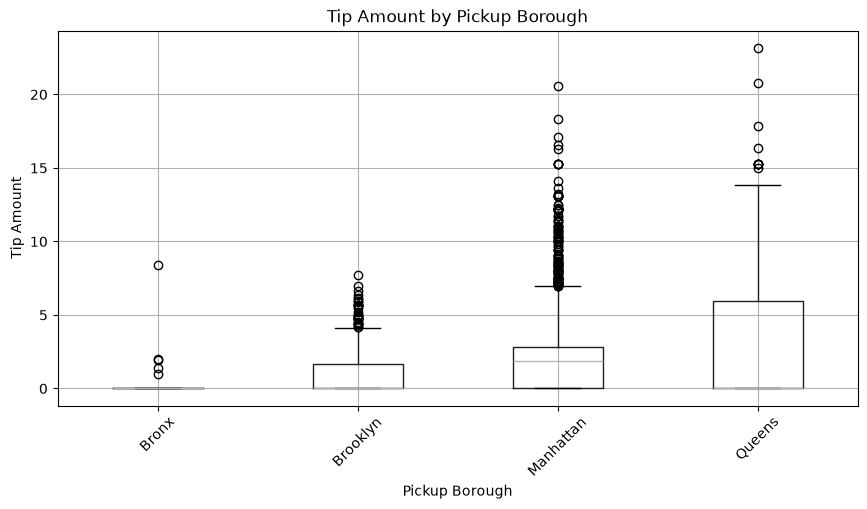

In [18]:
plt.figure(figsize=(10, 5))

df.boxplot(
    column='tip',
    by='pickup_borough',
    figsize=(10, 5)
)

plt.title('Tip Amount by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.xticks(rotation=45)
plt.show()

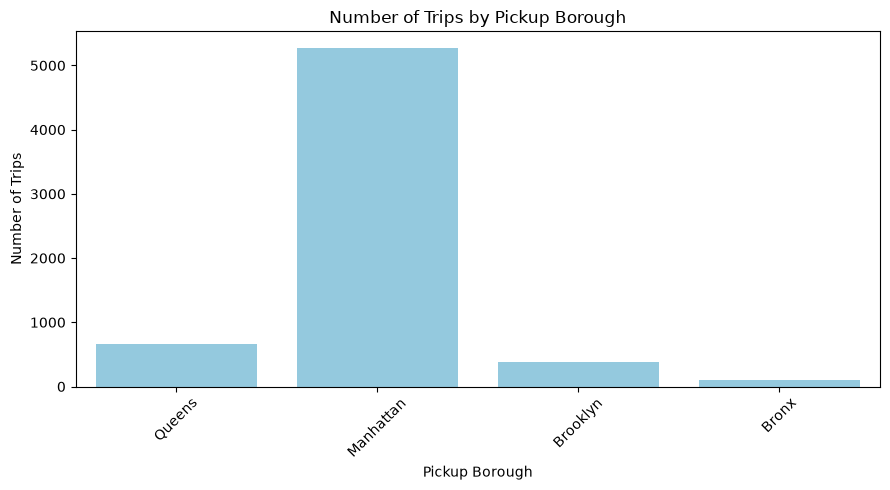

In [19]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='pickup_borough',
    color='skyblue'
)

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

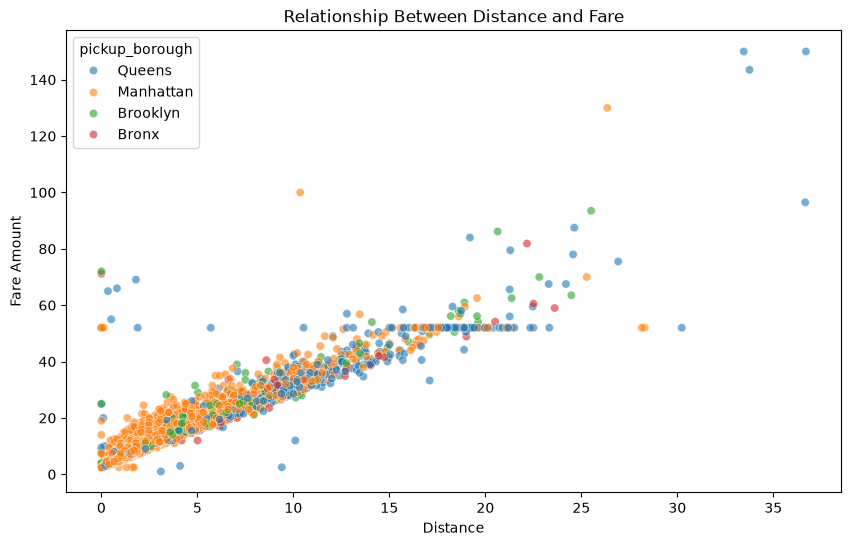

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough',
    alpha=0.6
)

plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare Amount')

plt.show()

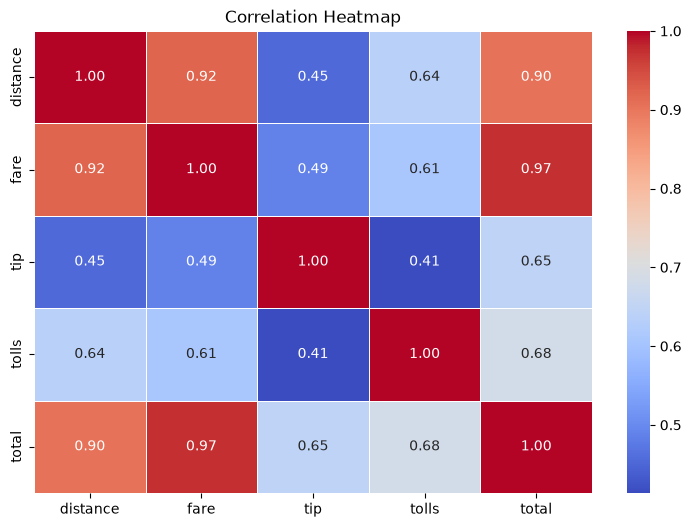

In [21]:
# Select numerical columns
numeric_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation matrix
corr_matrix = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

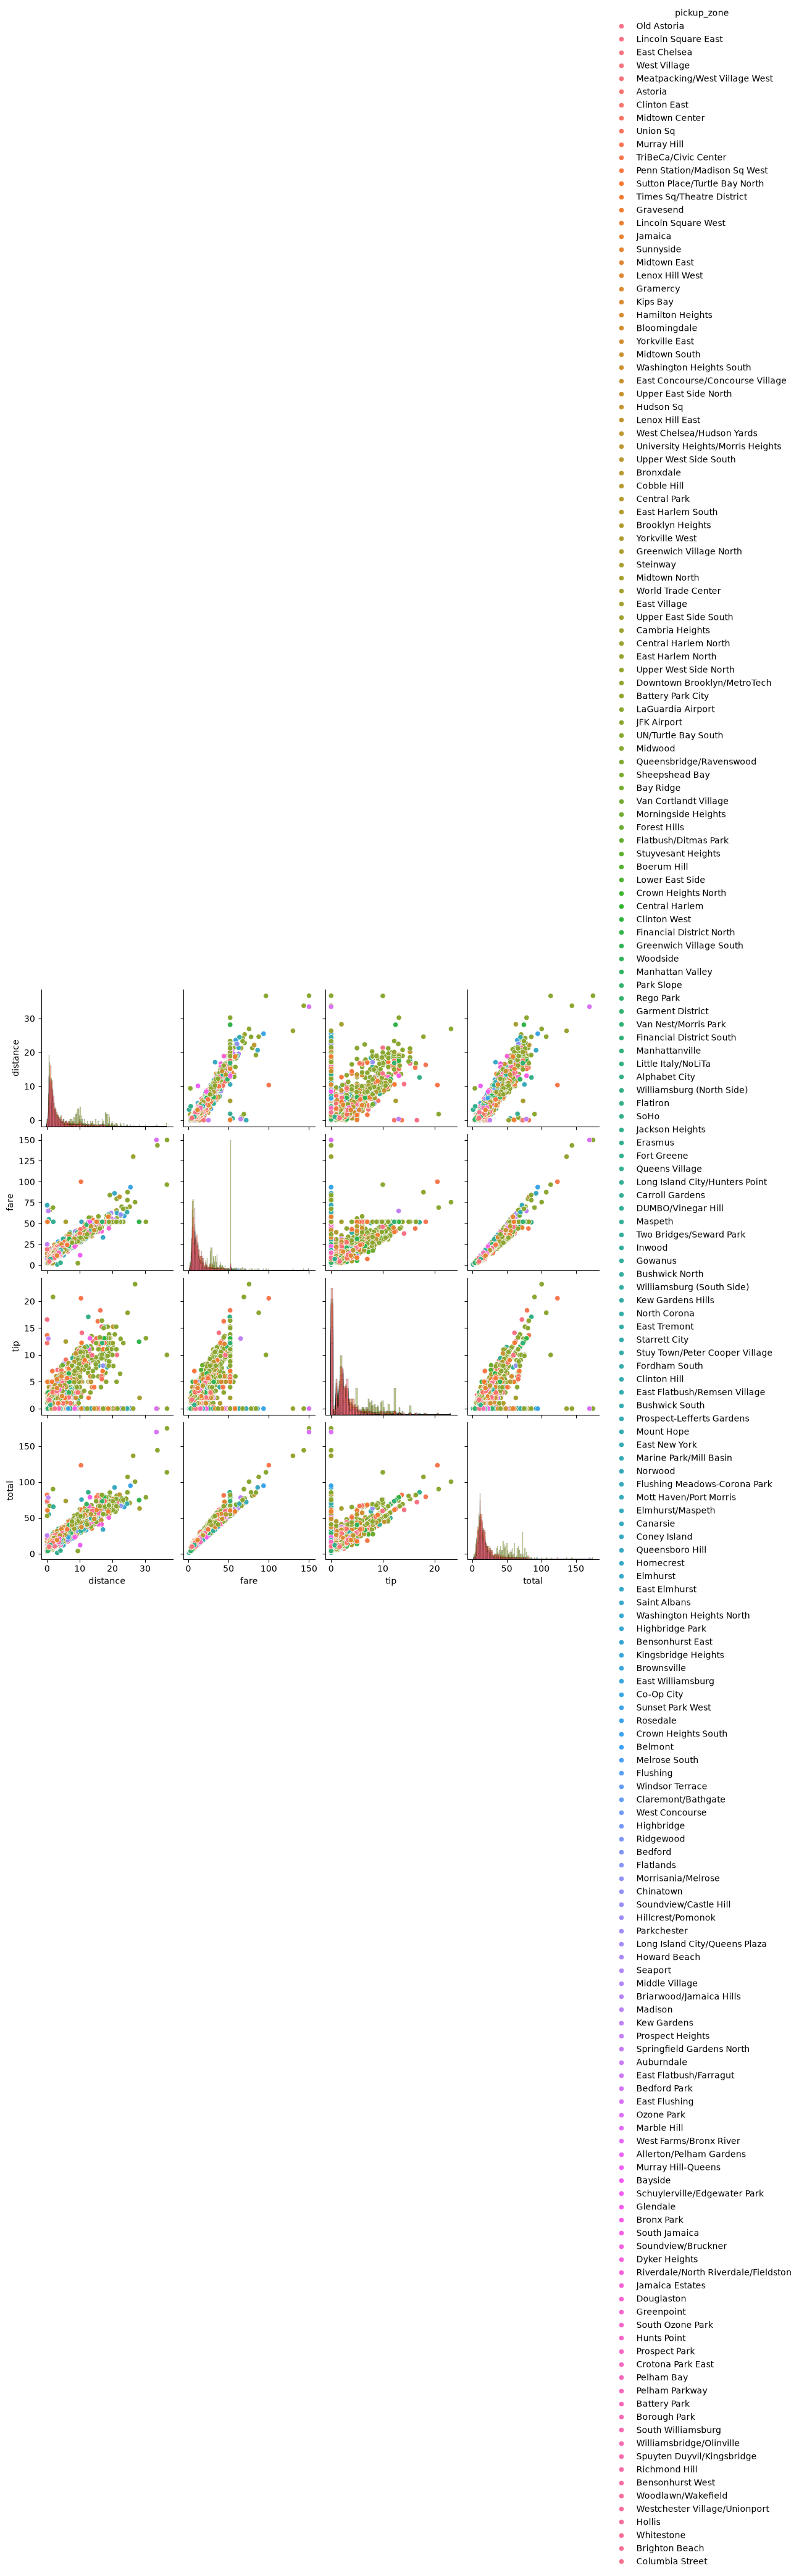

In [22]:
# Select required columns
pair_data = df[
    ['distance', 'fare', 'tip', 'total', 'pickup_zone']
].dropna()

# Create pair plot
sns.pairplot(
    pair_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone',
    diag_kind='hist'
)

plt.show()

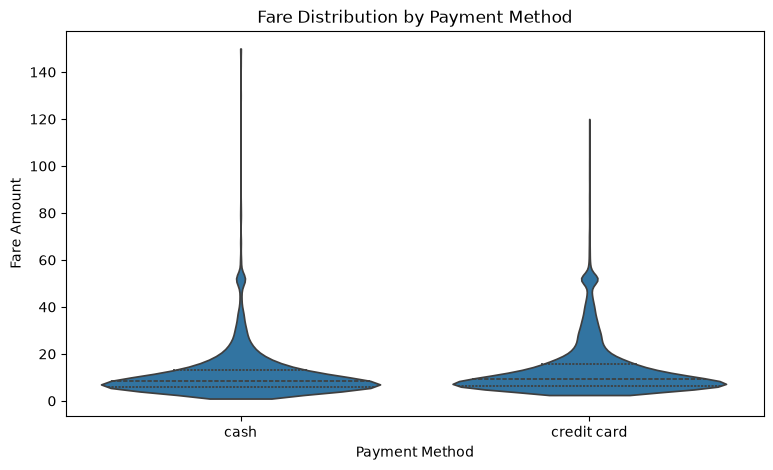

In [23]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare',
    inner='quartile',
    cut=0
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

plt.show()